In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from astropy.io import fits
from pathlib import Path

%matplotlib inline

mpl.rcParams.update({
    # Figure
    "figure.figsize":   (6, 4),
    "figure.dpi":       200,

    # Fonts
    "font.family":      "serif",
    "font.serif":       ["Times New Roman", "Palatino", "serif"],
    "font.size":        15,

    # Axes
    "axes.titlesize":   16,
    "axes.labelsize":   14,
    "axes.linewidth":   1.0,
    "axes.grid":        False,
    "axes.grid.axis":   "both",
    "axes.grid.which":  "both",
    "axes.prop_cycle":  mpl.cycler(
                            "color",
                            ["#1f77b4","#ff7f0e","#2ca02c",
                             "#d62728","#9467bd","#8c564b"]
                        ),

    # Grid
    "grid.linestyle":   "--",
    "grid.linewidth":   0.8,
    "grid.alpha":       0.7,

    # Lines & markers
    "lines.linewidth":  1.0,
    "lines.markersize": 6,

    # Ticks
    "xtick.direction":  "in",
    "ytick.direction":  "in",
    "xtick.labelsize":  11,
    "ytick.labelsize":  11,
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "xtick.minor.size": 3,
    "ytick.minor.size": 3,

    # Legend
    "legend.fontsize":  11,
    "legend.frameon":   False,

    # Image
    "image.cmap":       "viridis",
    "image.origin":		"lower"
})

## Notes For the Code Below

This is the site for the data that Dr. Mann shared with me: https://www2.keck.hawaii.edu/inst/kpf/
In it, it says that the scope "covers a wavelength range of 445 nm to 870 nm"

In the document it says that a Calcium H&K spectrum is also taken, but getting this data from the fits file yields that it is just empty? (See graphing section in the code)
Dr. Mann said that the wavelengths are not identical between fibers and exposures? I assume this means we need to somehow find the Ca H&K spectrum, use that to calibrate, then match the fiber data before median stacking.
He also said the "Simplest [way] is to interpolate to match before stacking, but consider what uncertainties that creates"


Y-axis is the order of the grating, not spatial information. We should analyze each order separately?
Green data has 35 orders, red data only 32. I say we only looks at orders 0-32 and leave out the last few of green so we can use all data

The below data is not sky subtracted. Reason being is that "the throughput of the sky fiber is slightly different. You might find you need to ’scale’ to match as part of the subtraction, or combine many sky spectra to get proper SNR."
I'm not sure how we can tell what the true sky level should be and what ratio to scale it by

In [3]:
## Given a folder path, opens each file in the folder and extracts the flux and wavelength data for both red and green channels
#	Returns a list of the green flux, red flux, green wavelength, red wavelength with each item in each being a different observation
def _open_files(folder_path):
	green_sci_flux = []
	red_sci_flux = []
	green_sci_wave = []
	red_sci_wave = []

	calibration_flux = []
	calibration_wave = []

	for file in folder_path.iterdir():
		with fits.open(file) as hdu:
			# hdu.info()

			flux = hdu['GREEN_SCI_FLUX1'].data
			flux2 = hdu['GREEN_SCI_FLUX2'].data
			flux3 = hdu['GREEN_SCI_FLUX3'].data
			green_sci_flux.append(flux + flux2 + flux3) # Emailed Dr. Mann and he said its best to sum the 3 fibers


			flux = hdu['RED_SCI_FLUX1'].data
			flux2 = hdu['RED_SCI_FLUX2'].data
			flux3 = hdu['RED_SCI_FLUX3'].data
			red_sci_flux.append(flux + flux2 + flux3) # Emailed Dr. Mann and he said its best to sum the 3 fibers

			wave = hdu['GREEN_SCI_WAVE1'].data
			wave2 = hdu['GREEN_SCI_WAVE2'].data
			wave3 = hdu['GREEN_SCI_WAVE3'].data
			green_sci_wave.append(wave + wave2 + wave3) # Emailed Dr. Mann and he said its best to sum the 3 fibers

			wave = hdu['RED_SCI_WAVE1'].data
			wave2 = hdu['RED_SCI_WAVE2'].data
			wave3 = hdu['RED_SCI_WAVE3'].data
			red_sci_wave.append(wave + wave2 + wave3) # Emailed Dr. Mann and he said its best to sum the 3 fibers


			## Extracting calibration data
			cal_flux = hdu['CA_HK_SCI'].data
			cal_wave = hdu['CA_HK_SCI_WAVE'].data
			calibration_flux.append(cal_flux)
			calibration_wave.append(cal_wave)

	return green_sci_flux, red_sci_flux, green_sci_wave, red_sci_wave, calibration_flux, calibration_wave




## Median stacks an array of data
def _median_stack(data_array):
	return np.median(data_array, axis=0)



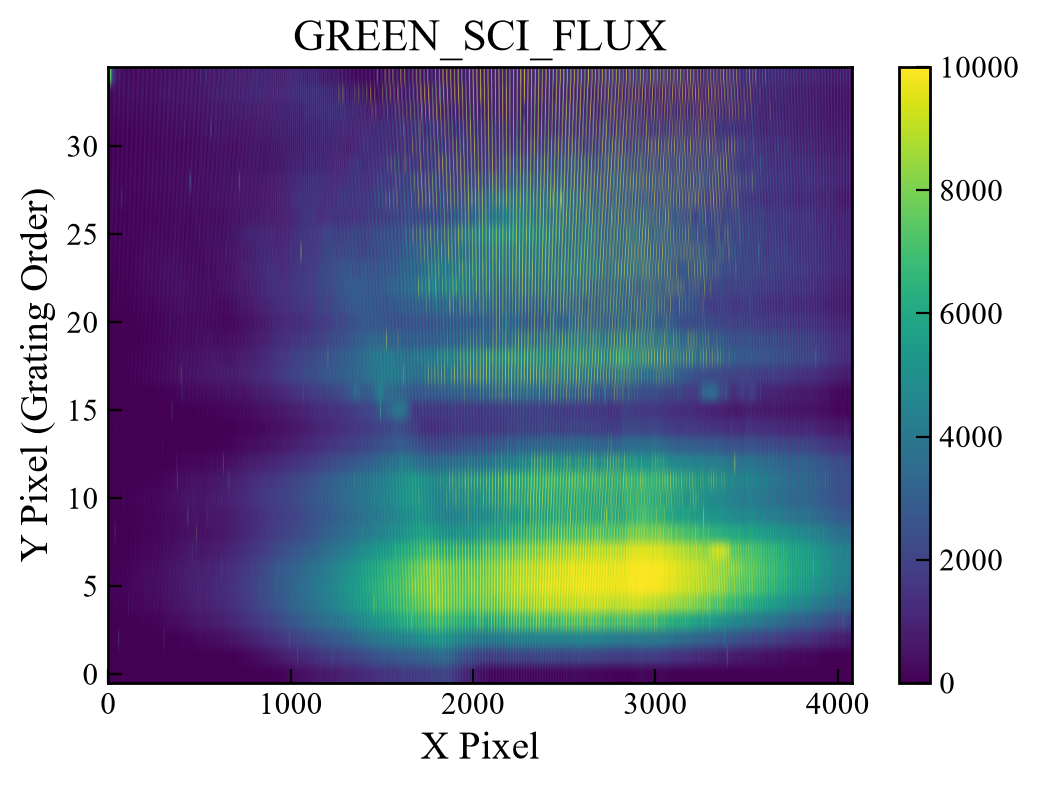

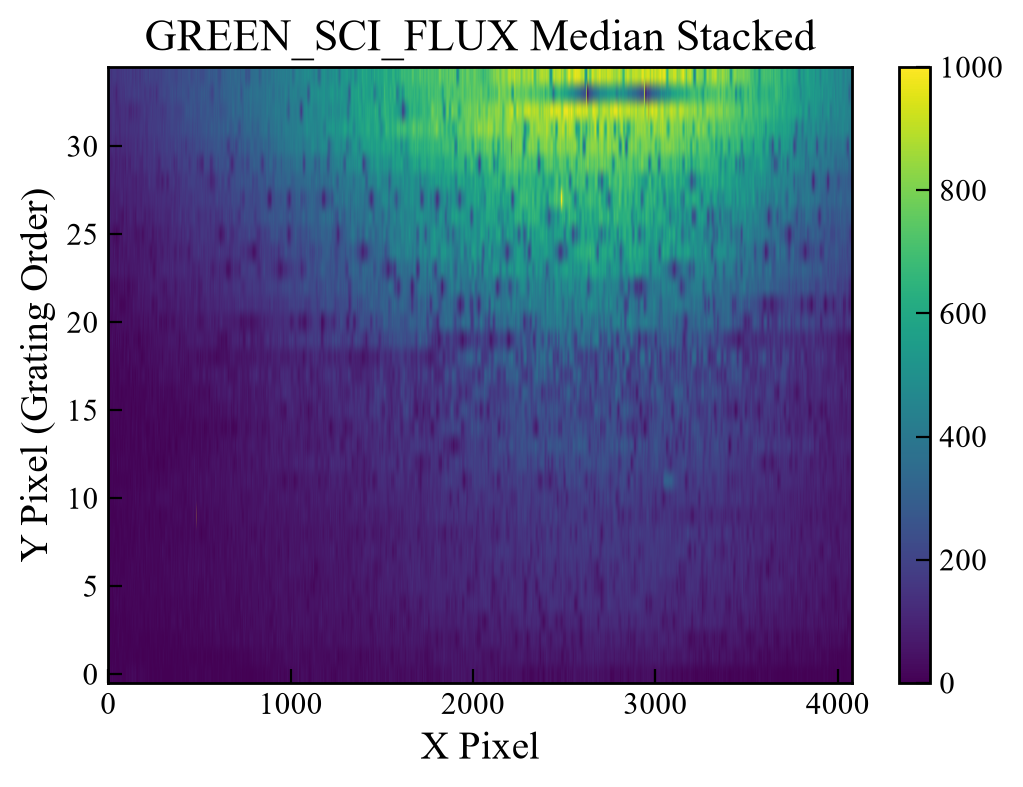

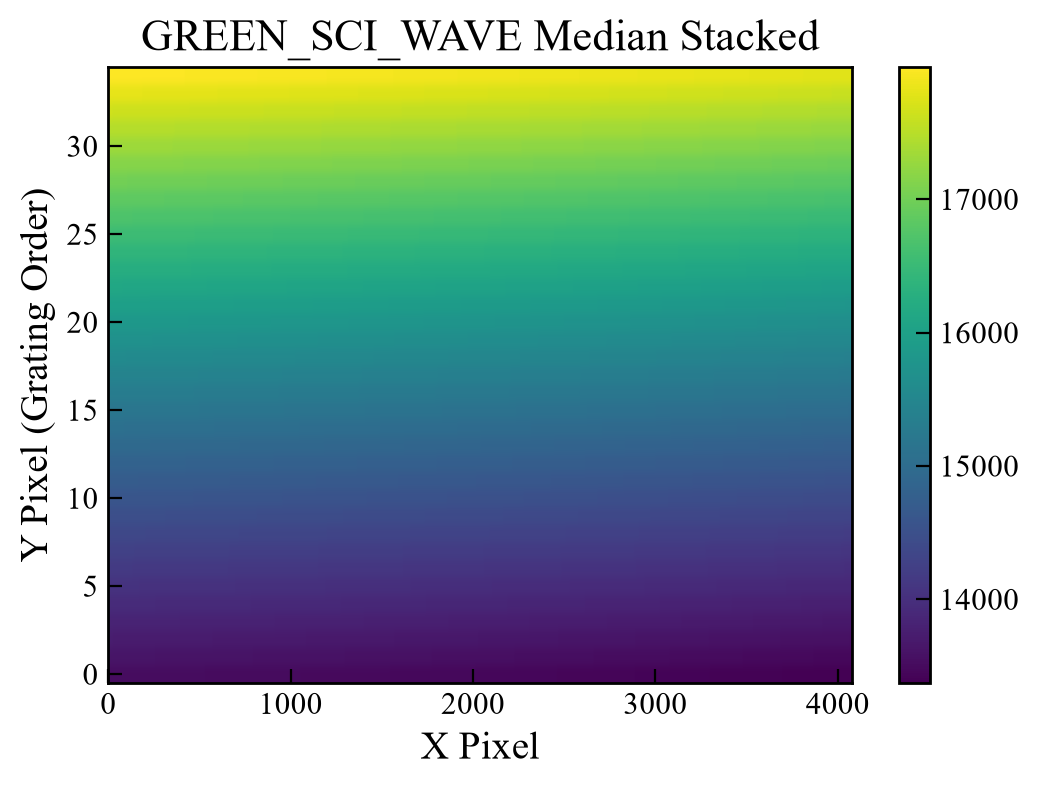

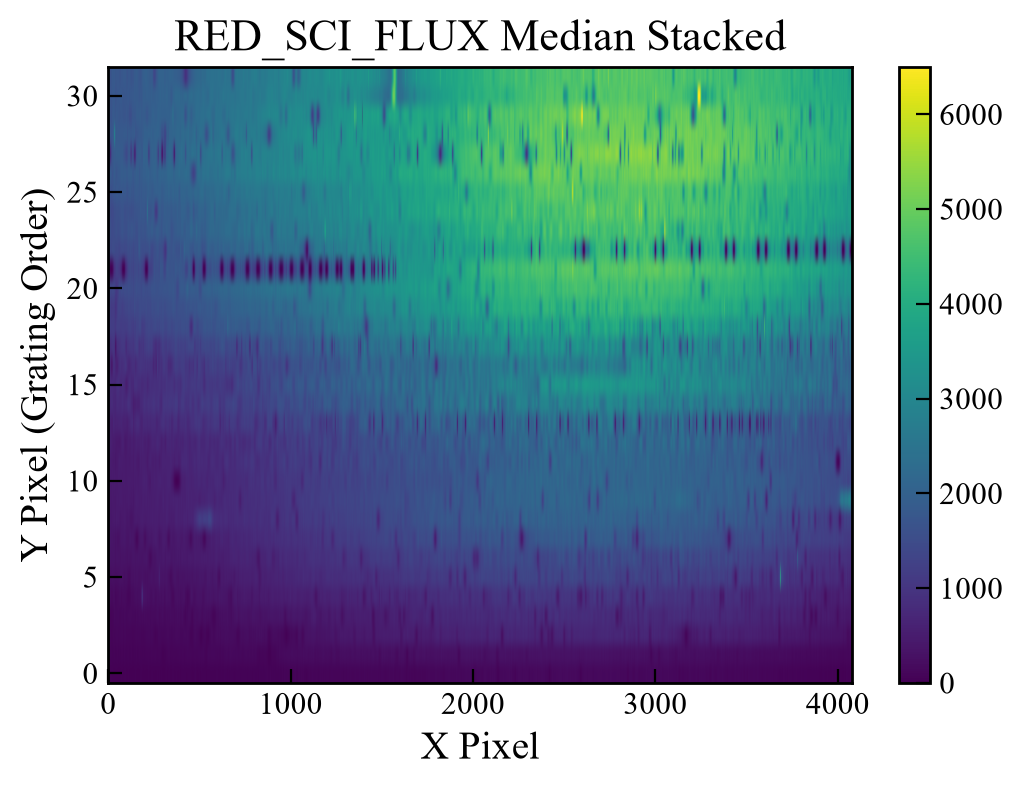

[]


In [4]:
### Open folders
night_1_folder = Path('L1/20241016')
night_2_folder = Path('L1/20250125')



## Extracting data for night 1 (each index of each list is a different observation in the same night)
g_flux_list, r_flux_list, g_wave_list, r_wave_list, cal_flux_list, cal_wave_list = _open_files(night_1_folder)

## Median stacking across all observations
g_flux_med = _median_stack(np.array(g_flux_list))
r_flux_med = _median_stack(np.array(r_flux_list))

g_wave_med = _median_stack(np.array(g_wave_list))
r_wave_med = _median_stack(np.array(r_wave_list))

cal_flux_med = _median_stack(np.array(cal_flux_list))
cal_wave_med = _median_stack(np.array(cal_wave_list))



## Show data (I'm a big visual guy)
plt.imshow(g_flux_list[1], vmin=0, vmax=10000, aspect='auto')
plt.title('GREEN_SCI_FLUX')
plt.xlabel('X Pixel')
plt.ylabel('Y Pixel (Grating Order)')
plt.colorbar()
plt.show()


plt.imshow(g_flux_med, vmin=0, vmax=1000, aspect='auto')
plt.title('GREEN_SCI_FLUX Median Stacked')
plt.xlabel('X Pixel')
plt.ylabel('Y Pixel (Grating Order)')
plt.colorbar()
plt.show()

plt.imshow(g_wave_med, aspect='auto')
plt.title('GREEN_SCI_WAVE Median Stacked')
plt.xlabel('X Pixel')
plt.ylabel('Y Pixel (Grating Order)')
plt.colorbar()
plt.show()

plt.imshow(r_flux_med, vmin=0, vmax=6500, aspect='auto')
plt.title('RED_SCI_FLUX Median Stacked')
plt.xlabel('X Pixel')
plt.ylabel('Y Pixel (Grating Order)')
plt.colorbar()
plt.show()


## Calibration data not graphable. Shape = (0,) ?
print(cal_flux_med)
# plt.imshow(cal_flux_med, aspect='auto')
# plt.title('CA_HK_SCI Median Stacked')
# plt.xlabel('X Pixel')
# plt.ylabel('Y Pixel (Grating Order)')
# plt.colorbar()
# plt.show()

## Order Grapher

Graphs the data at a given order

### Notes

The value of the wavelength range in pixel space is not the same for each order. See _test function to see what i mean.
If the wavelength range of the detector (445 to 870nm) stays constant over order, we can fit the range found in the _test function at each order to the detector range to fit all the data into wavelength space

On a second look through, I'm not entirely sure what the wave data I'm extracting from _order_extraction is. It't the value of the wavelength in the 3rd graph of the previous code block at a given order (row), but that value is much higher than any possible wavelength. I did the shifting thing (wave_O1_shifted) to make more sense of it since the data seemed to be graphed over a similar range for each order, and found some differences, but a second look makes me think I just did it to make sense of the data without thinking through it entirely. Someone please check and make sure my reasoning is correct.

Need to remove outliers (see _plot_all_orders)

161.48930362787542
162.69268688610646
163.90837467958772
165.14883988422116
166.40011985796264
167.68233389935267
168.97632515848272
170.29641715615253
171.63244555860183
172.98692621174996
174.36966023715104
175.77902984013053
177.27739269196172
178.72919986675697
180.20308615451177
181.70189244310131
183.22408273975452
184.77229450249615
186.34574575581064
187.9467717757252
189.57256617793246
191.22614684197833
192.90784124735
194.61897916995076
196.35931665649514
198.129212116517
199.92752281100184
201.75702919547257
203.6190799485994
205.513525191418
207.44229440064373
209.4022138779328
211.394547797805
213.42170709979837
215.4862030665463


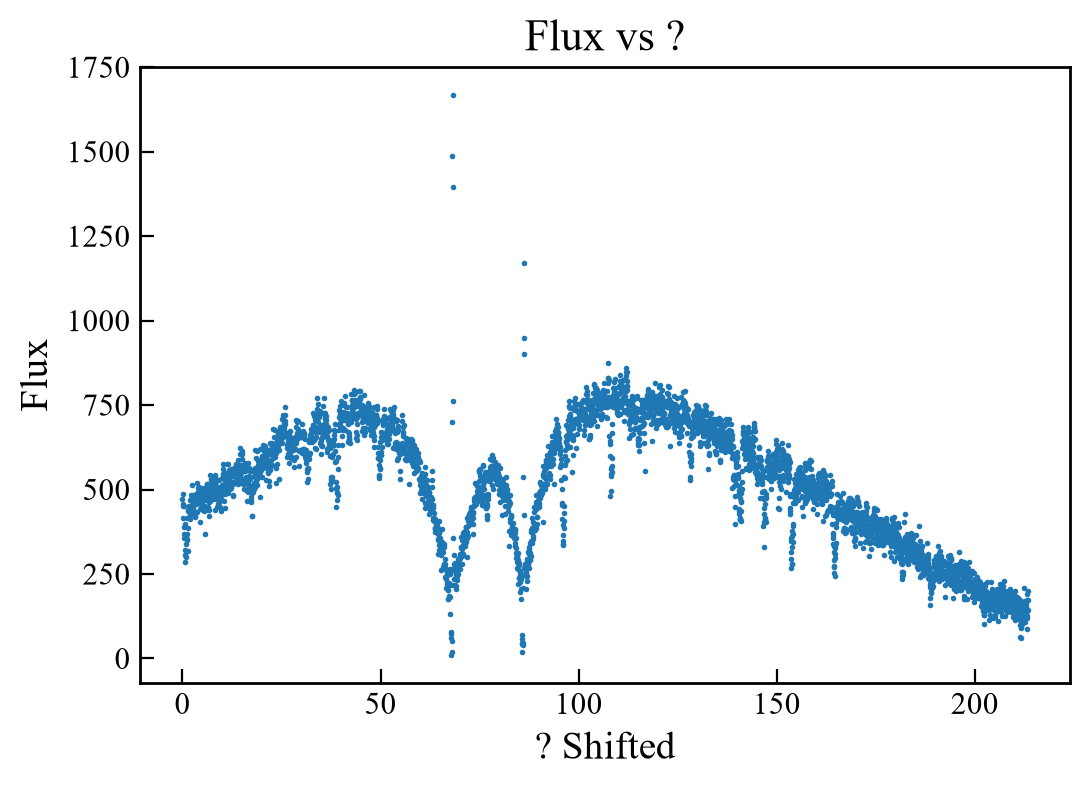

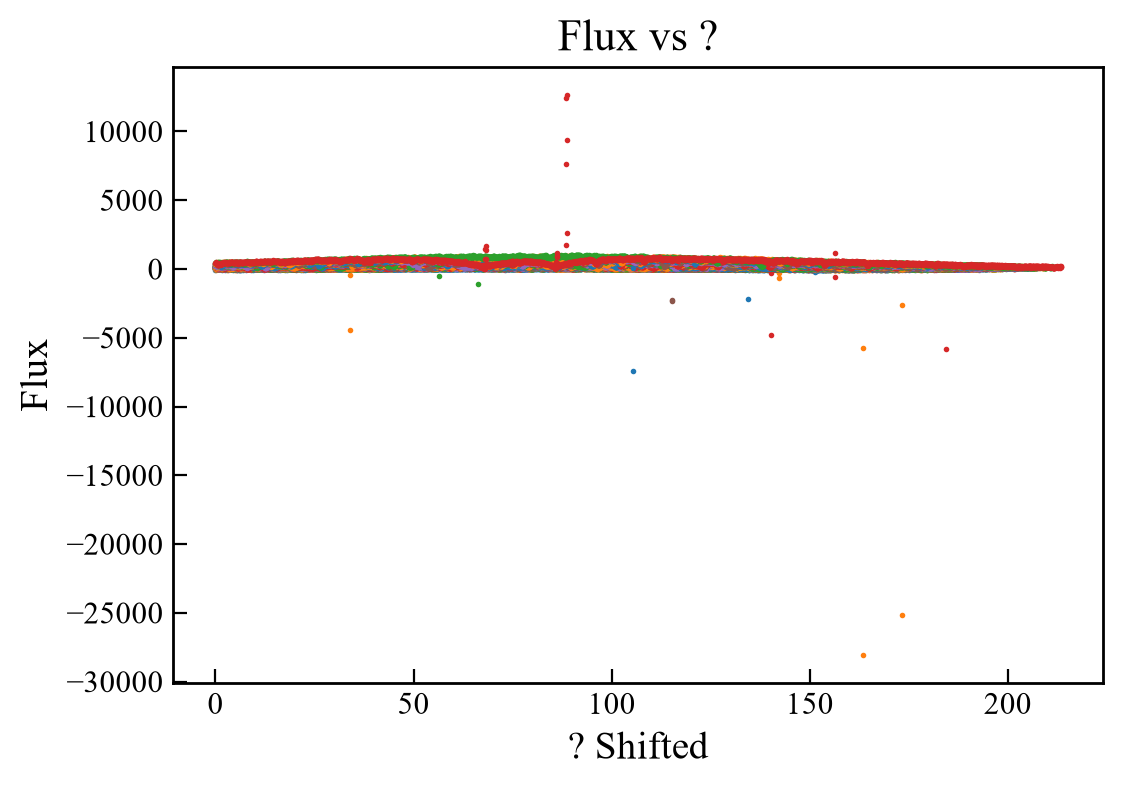

In [7]:
def _order_extraction(flux_im, wave_im, order):

	flux_order = flux_im[order,:]
	wave_order = wave_im[order,:]

	return flux_order, wave_order



def _test(flux_im, wave_im, o_min, o_max):
	for order in range(o_min, o_max):
		flux, wave = _order_extraction(flux_im, wave_im, order)
		wave_shifted = wave - min(wave)
		print(max(wave_shifted))

_test(g_flux_med, g_wave_med, 0, 35)



flux_O1, wave_O1 = _order_extraction(g_flux_med, g_wave_med, 33)
wave_O1_shifted = wave_O1 - min(wave_O1)
plt.scatter(wave_O1_shifted, flux_O1, s=1)
plt.title('Flux vs ?') # See markdown cell above
plt.xlabel('? Shifted') # See markdown cell above
plt.ylabel('Flux')
plt.show()




def _plot_all_orders(flux_im, wave_im, o_min, o_max):
	for order in range(o_min, o_max):
		flux, wave = _order_extraction(flux_im, wave_im, order)
		wave_shifted = wave - min(wave)
		plt.scatter(wave_shifted, flux, s=1)

	plt.title('Flux vs ?') # See markdown cell above
	plt.xlabel('? Shifted') # See markdown cell above
	plt.ylabel('Flux')
	plt.show()

_plot_all_orders(g_flux_med, g_wave_med, 0, 34)